**Environment check**

In [1]:
# check Python and library versions (proves the environment is ready)
import sys
import numpy
import pandas
import matplotlib
import seaborn

print("Python     :", sys.version.split()[0])
print("NumPy      :", numpy.__version__)
print("Pandas     :", pandas.__version__)
print("Matplotlib :", matplotlib.__version__)
print("Seaborn    :", seaborn.__version__)

Python     : 3.13.18
NumPy      : 2.1.3
Pandas     : 2.2.3
Matplotlib : 3.10.0
Seaborn    : 0.13.2


**Load and inspect the data**

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# built-in restaurant tips dataset
df = sns.load_dataset("tips")

print(df.head())
print("Shape:", df.shape)
print()
df.info()
print()
print(df.describe())
print()
print("Missing values:")
print(df.isnull().sum())

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
Shape: (244, 7)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB

       total_bill         tip        size
count  244.000000  244.000000  244.000000
mean    19.785943    2.998279

**Data manipulation**

In [3]:
# --- filtering ---
dinner = df[df["time"] == "Dinner"]
print("Dinner rows:", len(dinner))

big_bills = df[df["total_bill"] > 30]
print("Bills above 30:", len(big_bills))

# --- sorting: top 5 biggest bills ---
top5 = df.sort_values("total_bill", ascending=False).head(5)
print(top5)

# --- new columns ---
df["tip_percent"] = (df["tip"] / df["total_bill"] * 100).round(2)
df["bill_per_person"] = (df["total_bill"] / df["size"]).round(2)
print(df[["total_bill", "tip", "tip_percent", "bill_per_person"]].head())

# --- groupby ---
print("\nAverage bill by day:")
print(df.groupby("day", observed=True)["total_bill"].mean().round(2))

print("\nAverage tip % by time:")
print(df.groupby("time", observed=True)["tip_percent"].mean().round(2))

print("\nNumber of orders by day and time:")
print(df.groupby(["day", "time"], observed=True).size())

Dinner rows: 176
Bills above 30: 32
     total_bill    tip   sex smoker  day    time  size
170       50.81  10.00  Male    Yes  Sat  Dinner     3
212       48.33   9.00  Male     No  Sat  Dinner     4
59        48.27   6.73  Male     No  Sat  Dinner     4
156       48.17   5.00  Male     No  Sun  Dinner     6
182       45.35   3.50  Male    Yes  Sun  Dinner     3
   total_bill   tip  tip_percent  bill_per_person
0       16.99  1.01         5.94             8.49
1       10.34  1.66        16.05             3.45
2       21.01  3.50        16.66             7.00
3       23.68  3.31        13.98            11.84
4       24.59  3.61        14.68             6.15

Average bill by day:
day
Thur    17.68
Fri     17.15
Sat     20.44
Sun     21.41
Name: total_bill, dtype: float64

Average tip % by time:
time
Lunch     16.41
Dinner    15.95
Name: tip_percent, dtype: float64

Number of orders by day and time:
day   time  
Thur  Lunch     61
      Dinner     1
Fri   Lunch      7
      Dinner    12


**Visualizations**

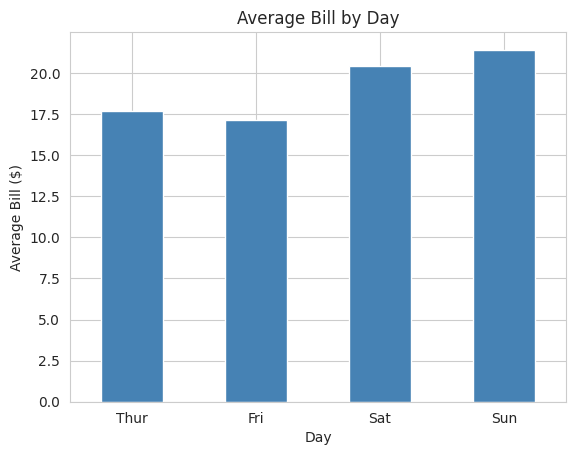

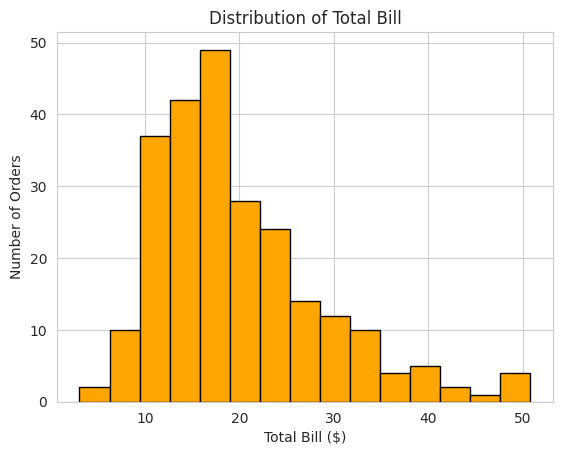

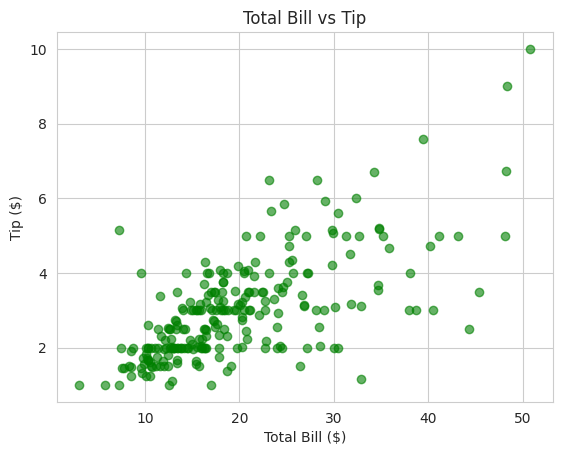

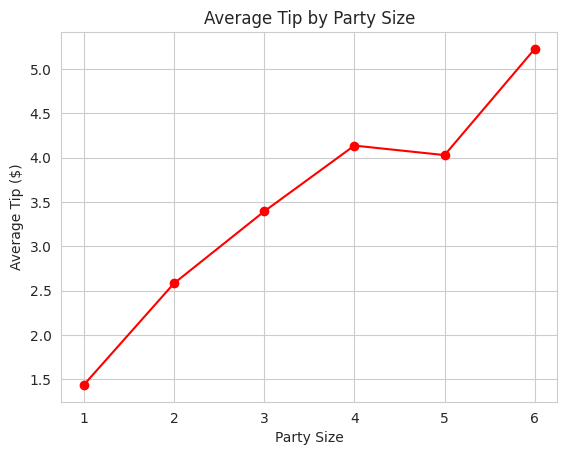

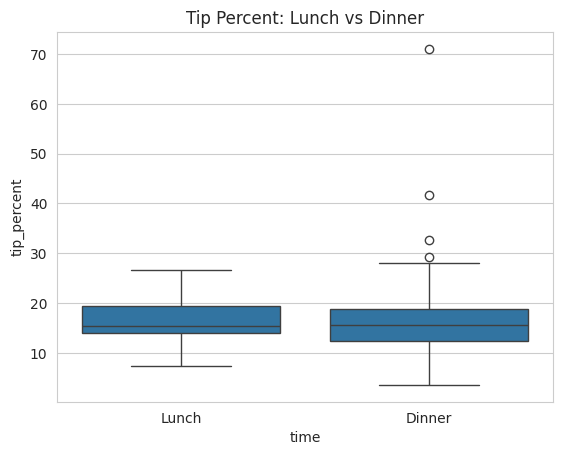

In [4]:
sns.set_style("whitegrid")

# 1. bar chart: average bill by day
df.groupby("day", observed=True)["total_bill"].mean().plot(kind="bar", color="steelblue")
plt.title("Average Bill by Day")
plt.xlabel("Day")
plt.ylabel("Average Bill ($)")
plt.xticks(rotation=0)
plt.show()

# 2. histogram: distribution of bills
plt.hist(df["total_bill"], bins=15, color="orange", edgecolor="black")
plt.title("Distribution of Total Bill")
plt.xlabel("Total Bill ($)")
plt.ylabel("Number of Orders")
plt.show()

# 3. scatter plot: bill vs tip
plt.scatter(df["total_bill"], df["tip"], color="green", alpha=0.6)
plt.title("Total Bill vs Tip")
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")
plt.show()

# 4. line chart: average tip by party size
df.groupby("size")["tip"].mean().plot(kind="line", marker="o", color="red")
plt.title("Average Tip by Party Size")
plt.xlabel("Party Size")
plt.ylabel("Average Tip ($)")
plt.show()

# 5. box plot: tip percent for lunch vs dinner
sns.boxplot(x="time", y="tip_percent", data=df)
plt.title("Tip Percent: Lunch vs Dinner")
plt.show()

**Basic analysis**

In [5]:
# correlation between bill and tip
corr = df["total_bill"].corr(df["tip"])
print("Correlation (bill vs tip):", round(corr, 2))

print("Average tip %:", round(df["tip_percent"].mean(), 2))
print("Busiest day:", df["day"].value_counts().idxmax())

print("\nAverage tip % smokers vs non-smokers:")
print(df.groupby("smoker", observed=True)["tip_percent"].mean().round(2))

print("\nAverage bill by party size:")
print(df.groupby("size")["total_bill"].mean().round(2))

print("\nNote: correlation does not mean causation.")

Correlation (bill vs tip): 0.68
Average tip %: 16.08
Busiest day: Sat

Average tip % smokers vs non-smokers:
smoker
Yes    16.32
No     15.93
Name: tip_percent, dtype: float64

Average bill by party size:
size
1     7.24
2    16.45
3    23.28
4    28.61
5    30.07
6    34.83
Name: total_bill, dtype: float64

Note: correlation does not mean causation.
